# 06 — Operação: cotação e monitoramento

## Parte A — Cotação de grupo novo

A ferramenta do dia a dia: recebe o censo de vidas de um grupo e devolve a taxa pura e a comercial (mensal, por mil de
capital), a decomposição do custo e os alertas de subscrição. **Não exige R**: usa só a tabela de fatores da taxa
manual (04) e a tábua.

$$
\text{prêmio puro} = \sum_{\text{vidas}} q_x \cdot f_{\text{manual}} \cdot \min(C, P) \;+\; \underbrace{\sum_{\text{vidas}} q_x \cdot f_{\text{manual}} \cdot \max(C - P, 0)}_{\text{encargo de pooling}},
\qquad
\text{taxa comercial} = \text{taxa pura}\cdot\frac{1 + \text{margem}}{1 - \text{carregamentos}}
$$

em que $f_{\text{manual}}$ é o fator da taxa manual (A/E base × seção × divisão × capital) e $P$ o nível de pooling do
grupo. Carregamentos e limites dos alertas estão em `config/cotador.yaml` e são **política da seguradora** (valores
ilustrativos).

In [1]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M
from vgpricing.cotador import cotar
from vgpricing.io import ler_excel

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cc, cr, mapas = (carregar_config(n, RAIZ) for n in ("base", "cotador", "renovacao", "colunas"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")
print("Taxa manual:", tabela["meta"]["modelo_escolhido"], "| experiência até", tabela["meta"]["corte_experiencia"])

Taxa manual: GLM | experiência até 2024-12-31


## 1. Entrada

Na operação, o censo vem do template Excel (`templates/entrada_vida_grupo.xlsx`, abas `estipulantes` e `vidas`):

```python
dados, problemas = ler_excel("cotacao_cliente.xlsx", mapas)
censo, estip = dados["vidas"], dados["estipulantes"].iloc[0]
```

Aqui, para demonstrar, o censo é o de um grupo da carteira sintética, cotado como se fosse novo.

In [2]:
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
vidas, estips = pd.read_parquet(limpo / "vidas.parquet"), pd.read_parquet(limpo / "estipulantes.parquet")
ativos = vidas[vidas["data_fim"].isna()]
porte = ativos["id_estipulante"].value_counts()
exemplos = {"pequeno": porte.index[int(len(porte) * 0.9)], "mediano": porte.index[len(porte) // 2], "grande": porte.index[5]}
INICIO = pd.Timestamp(cfg["data_referencia"]) + pd.Timedelta(days=1)
linhas, alertas = [], {}
for nome, g in exemplos.items():
    censo = ativos[ativos["id_estipulante"] == g][["data_nascimento", "sexo", "capital"]]
    e = estips.set_index("id_estipulante").loc[g]
    r = cotar(censo, e["cnae_secao"], e["cnae_divisao"], tabela, tabua, INICIO, cc, cr)
    alertas[nome] = r.pop("alertas")
    linhas.append({"grupo": f"{nome} ({g})", "atividade": f"{e['cnae_secao']}:{e['cnae_divisao']}", **r})
cot = pd.DataFrame(linhas).set_index("grupo")
cot[["atividade", "vidas", "capital_total", "nivel_pooling", "encargo_pooling", "premio_puro_anual",
     "taxa_pura_mensal_mil", "taxa_comercial_mensal_mil"]]

,atividade,vidas,capital_total,nivel_pooling,encargo_pooling,premio_puro_anual,taxa_pura_mensal_mil,taxa_comercial_mensal_mil
grupo,,,,,,,,
pequeno (EST0048),K:64,62,"3,420,000.0000","165,483.8710",0.0000,"4,949.7534",0.1206,0.1938
mediano (EST0013),G:46,468,"90,145,600.0000","577,856.4103","2,020.0586","120,159.5929",0.1111,0.1785
grande (EST0092),G:45,4862,"97,240,000.0000","100,000.0000",0.0000,"161,370.6767",0.1383,0.2222


### A.2 Com o histórico do grupo: validação em grupos novos simulados

Na subscrição, além do censo, chega a **sinistralidade dos últimos anos** do grupo na seguradora atual: sinistros por
ano, avisados até a data da cotação. Ela entra com a credibilidade da renovação,
$\text{fator} = Z\,A/E + (1 - Z)$, $Z = n_{ef}/(n_{ef} + k)$, com o $k$ de Bühlmann-Straub da carteira
(`artefatos/credibilidade.yaml`, gravado no 05). O último ano do histórico ainda está incompleto (IBNR): os sinistros de
cada ano são divididos pela proporção que já deveria estar avisada, pelo padrão de aviso da carteira.

**Como se valida isso?** Simulando grupos que **não** estão na carteira, cada um com três anos numa "seguradora
anterior" e um ano seguinte. A cotação recebe só o que a subscrição recebe (censo e histórico avisado); o ano seguinte,
que ela não vê, é a verdade. Comparam-se: só a taxa manual, a taxa com o histórico ponderado pela credibilidade (com e
sem completar o IBNR) e só o histórico.

In [3]:
from joblib import Memory
from vgpricing.sintetico import gerar_pacotes_cotacao
from vgpricing.cotador import completar_ibnr
from vgpricing.ibnr import padrao_aviso
from vgpricing import avaliacao as A
cs = carregar_config("sintetico", RAIZ)
cache = Memory(RAIZ / "data/processed/cache", verbose=0).cache
pac = cache(gerar_pacotes_cotacao)(cs, tabua, 400, 3, cr["pooling"])
cred = M.carregar_tabela(RAIZ / "artefatos/credibilidade.yaml")
padrao = padrao_aviso(pd.read_parquet(limpo / "sinistros.parquet"), cfg["data_referencia"])

def cotar_pacotes(pac, tabela, k):
    linhas = []
    for g, e in pac["estipulantes"].set_index("id_estipulante").iterrows():
        censo = pac["censos"][pac["censos"]["id_estipulante"] == g][["data_nascimento", "sexo", "capital"]]
        if censo.empty:
            continue
        h0 = pac["historico"][pac["historico"]["id_estipulante"] == g].rename(
            columns={"sinistros": "sinistros_brutos", "sinistros_limitados": "sinistros"})   # limitados ao pooling
        h = completar_ibnr(h0, padrao, e["data_cotacao"])
        q = lambda hist, kk: cotar(censo, e["cnae_secao"], e["cnae_divisao"], tabela, tabua, e["data_cotacao"], cc, cr, hist, kk)
        com = q(h, k)
        linhas.append({"id_estipulante": g, "vidas": len(censo), "Z": com["experiencia"]["Z"],
                       "mu_manual": q(None, None)["obitos_previstos"], "mu_sem_ibnr": q(h0, k)["obitos_previstos"],
                       "mu_cred": com["obitos_previstos"], "mu_hist": q(h, 1e-9)["obitos_previstos"]})
    return pd.DataFrame(linhas).merge(pac["realizado"], on="id_estipulante")

cv = cache(cotar_pacotes)(pac, tabela, cred["k_bs"])
PREV_C = {"só taxa manual": "mu_manual", "manual + histórico, sem completar o IBNR": "mu_sem_ibnr",
          "manual + histórico (credibilidade)": "mu_cred", "só histórico": "mu_hist"}
comp_c = A.comparar_modelos(cv, PREV_C, "só taxa manual", obs="N")
comp_c["A/M total"] = [cv["N"].sum() / cv[c].sum() for c in PREV_C.values()]
comp_c.to_csv(RAIZ / "resultados/operacao_cotacao_validacao.csv", index=False)
print(f"{len(cv)} grupos novos; {int(cv['N'].sum())} óbitos no ano cotado; Z mediano {cv['Z'].median():.2f}")
comp_c

400 grupos novos; 805 óbitos no ano cotado; Z mediano 0.11


,modelo,deviance,diferença vs só taxa manual,IC95 inf,IC95 sup,significativa,A/M total
0,só taxa manual,436.2801,0.0000,0.0000,0.0000,False,0.9969
1,"manual + histórico, sem completar o IBNR",422.6642,-13.6160,-40.0529,11.8469,False,1.0370
2,manual + histórico (credibilidade),423.5357,-12.7444,-39.4467,12.4786,False,1.0178
3,só histórico,"1,730.6740","1,294.3938",826.2681,"1,837.1772",True,1.0334


In [4]:
cv["faixa de Z"] = pd.cut(cv["Z"], [0, 0.1, 0.3, 1], labels=["Z < 0,1", "0,1 a 0,3", "Z > 0,3"], include_lowest=True)
pd.DataFrame({f: {"grupos": len(d), "óbitos": int(d["N"].sum()),
                  "deviance: só manual": A.deviance_poisson(d["N"], d["mu_manual"]),
                  "deviance: com credibilidade": A.deviance_poisson(d["N"], d["mu_cred"])}
              for f, d in cv.groupby("faixa de Z", observed=True)}).T

,grupos,óbitos,deviance: só manual,deviance: com credibilidade
"Z < 0,1",195.0000,56.0000,130.4681,131.1589
"0,1 a 0,3",94.0000,133.0000,110.1796,108.8920
"Z > 0,3",111.0000,616.0000,195.6325,183.4849


**Leitura.** Usar **só o histórico** é muito pior que a taxa manual: a sinistralidade de poucos anos de um grupo é
dominada por sorte. Com a credibilidade, o histórico melhora a previsão, mas pouco na maioria dos grupos, cujo Z é baixo;
o ganho se concentra nos grupos com mais óbitos efetivos (faixa de Z mais alta), como a teoria prevê. **Completar o
IBNR** do histórico corrige o viés de nível (A/M mais perto de 1): sem isso, o último ano incompleto puxa a taxa para
baixo. Na base real, o mesmo teste roda com as cotações da seguradora e o ano seguinte efetivamente observado.

## 2. Alertas de subscrição

In [5]:
pd.concat(alertas, names=["grupo"]).reset_index(level=0).query("disparou")[["grupo", "alerta", "detalhe"]]

,grupo,alerta,detalhe
2,pequeno,concentração: 10 maiores capitais,10 maiores = 38.6% do total


Os alertas não mudam a taxa: indicam o que a subscrição precisa olhar antes de emitir (resseguro facultativo para
capitais acima da retenção, concentração que torna o resultado do grupo dependente de poucas vidas, idades fora da
aceitação, grupo pequeno demais para a taxa média).

## 3. De onde vem a taxa (decomposição para o corretor ou o subscritor)

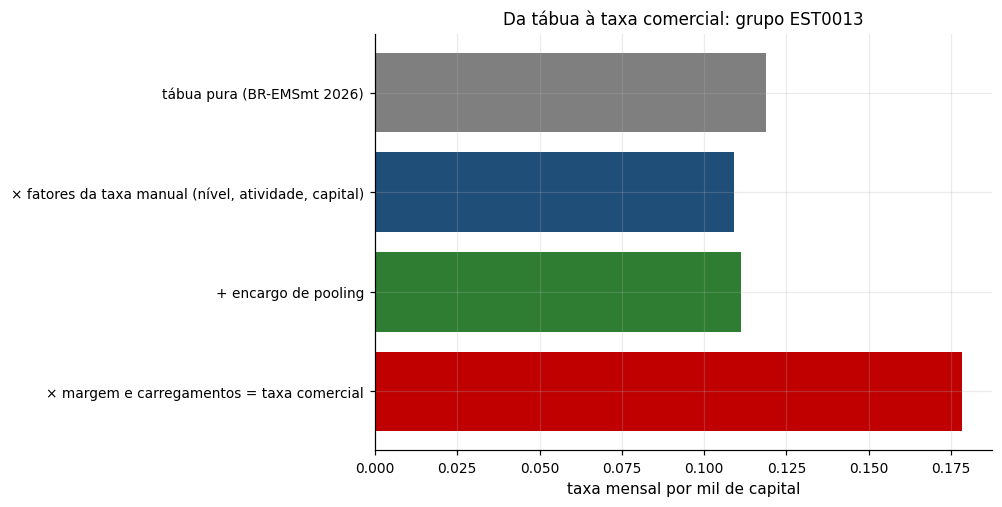

,taxa mensal (‰)
tábua pura (BR-EMSmt 2026),0.1189
"× fatores da taxa manual (nível, atividade, capital)",0.1092
+ encargo de pooling,0.1111
× margem e carregamentos = taxa comercial,0.1785


In [6]:
g = exemplos["mediano"]
censo = ativos[ativos["id_estipulante"] == g][["data_nascimento", "sexo", "capital"]]
e = estips.set_index("id_estipulante").loc[g]
r = cotar(censo, e["cnae_secao"], e["cnae_divisao"], tabela, tabua, INICIO, cc, cr)
tabua_pura = M.taxa_pura_manual(censo, e["cnae_secao"], e["cnae_divisao"],
                                {**tabela, "ae_base": 1.0, "secao": {}, "secao_nao_vista": 1.0,
                                 "capital": {**tabela["capital"], "elasticidade": 0.0}}, tabua, INICIO)
passos = pd.Series({"tábua pura (BR-EMSmt 2026)": tabua_pura["taxa_pura_mensal_mil"],
                    "× fatores da taxa manual (nível, atividade, capital)": r["taxa_pura_mensal_mil"] - r["encargo_pooling"] / r["capital_total"] * 1000 / 12,
                    "+ encargo de pooling": r["taxa_pura_mensal_mil"],
                    "× margem e carregamentos = taxa comercial": r["taxa_comercial_mensal_mil"]})
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(range(len(passos)), passos.values, color=["#7f7f7f", "#1f4e79", "#2e7d32", "#c00000"])
ax.set_yticks(range(len(passos)), passos.index); ax.invert_yaxis()
ax.set_xlabel("taxa mensal por mil de capital"); ax.set_title(f"Da tábua à taxa comercial: grupo {g}")
plt.show()
passos.to_frame("taxa mensal (‰)")

## Parte B — Monitoramento e gatilhos de revisão

A taxa manual em produção é acompanhada mês a mês. Três peças:
1. **A/E da carteira contra a taxa manual**, mês a mês e nos últimos 12 meses maduros, com limites de controle de 95% e
   99,8% (quantis exatos de Poisson dado o esperado). Os meses mais recentes, ainda sem todos os avisos, são completados
   pelo padrão de aviso (IBNR) e ficam fora do A/E móvel.
2. **Funnel plot dos grupos** (Spiegelhalter, 2005): A/E de cada estipulante contra o seu esperado, com limites que
   incluem a variância entre grupos (em vida em grupo, cada grupo tem mortalidade própria; sem isso, o funil
   "dispararia" sempre).
3. **Gatilhos objetivos** (`config/monitoramento.yaml`), cada um com a ação correspondente.

In [7]:
import sys, warnings
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from vgpricing.graficos import estilo
estilo()
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from joblib import Memory
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, monitoramento as Mo

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
cfg, cmo = carregar_config("base", RAIZ), carregar_config("monitoramento", RAIZ)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
limpo = RAIZ / cfg["pasta_processados"] / "limpo"
dados = {t: pd.read_parquet(limpo / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")
cache = Memory(RAIZ / "data/processed/cache", verbose=0).cache
serie = cache(Mo.serie_mensal)(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua, tabela,
                               cfg["data_referencia"], cmo["meses"])
J, NIV, IM = cmo["janela_meses"], cmo["niveis"], cmo["meses_imaturos"]
cart = Mo.carteira_mensal(serie, NIV, J, IM)
grupos = Mo.funil(serie, NIV, J, IM)

### B1. A/E da carteira contra a taxa manual

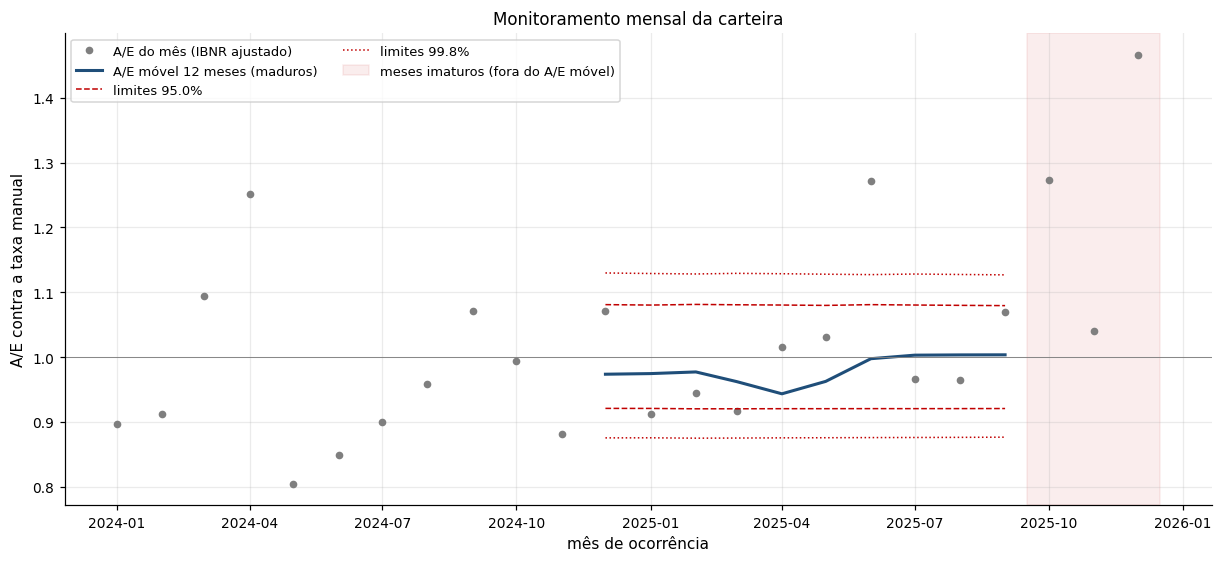

,E_manual,N,N_ajustado,A/E,imaturo,A/E 12m,lim inf 95.0%,lim sup 95.0%,lim inf 99.8%,lim sup 99.8%
mes,,,,,,,,,,
2025-07,52.579,46.000,50.828,0.967,False,1.003,0.921,1.080,0.876,1.128
2025-08,52.747,44.000,50.918,0.965,False,1.004,0.921,1.080,0.876,1.128
2025-09,51.249,44.000,54.813,1.070,False,1.004,0.921,1.080,0.877,1.127
2025-10,53.210,47.000,67.756,1.273,True,NaN,NaN,NaN,NaN,NaN
2025-11,51.759,26.000,53.814,1.040,True,NaN,NaN,NaN,NaN,NaN
2025-12,53.823,12.000,78.921,1.466,True,NaN,NaN,NaN,NaN,NaN


In [8]:
x = cart.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(x, cart["A/E"], "o", color="#7f7f7f", ms=4, label="A/E do mês (IBNR ajustado)")
ax.plot(x, cart[f"A/E {J}m"], "-", color="#1f4e79", lw=2, label=f"A/E móvel {J} meses (maduros)")
for n, estilo_l in zip(NIV, ["--", ":"]):
    ax.plot(x, cart[f"lim inf {n:.1%}"], estilo_l, color="#c00000", lw=1, label=f"limites {n:.1%}")
    ax.plot(x, cart[f"lim sup {n:.1%}"], estilo_l, color="#c00000", lw=1)
im = cart["imaturo"]
ax.axvspan(x[im].min() - pd.Timedelta(days=15), x[im].max() + pd.Timedelta(days=15), color="#c00000", alpha=0.07,
           label=f"meses imaturos (fora do A/E móvel)")
ax.axhline(1, color="grey", lw=0.6)
ax.set_xlabel("mês de ocorrência"); ax.set_ylabel("A/E contra a taxa manual")
ax.set_title("Monitoramento mensal da carteira"); ax.legend(ncol=2)
fig.savefig(RAIZ / "docs/figuras/operacao_monitoramento.png", dpi=110)
plt.show()
cart.tail(6)

### B2. Funnel plot dos grupos

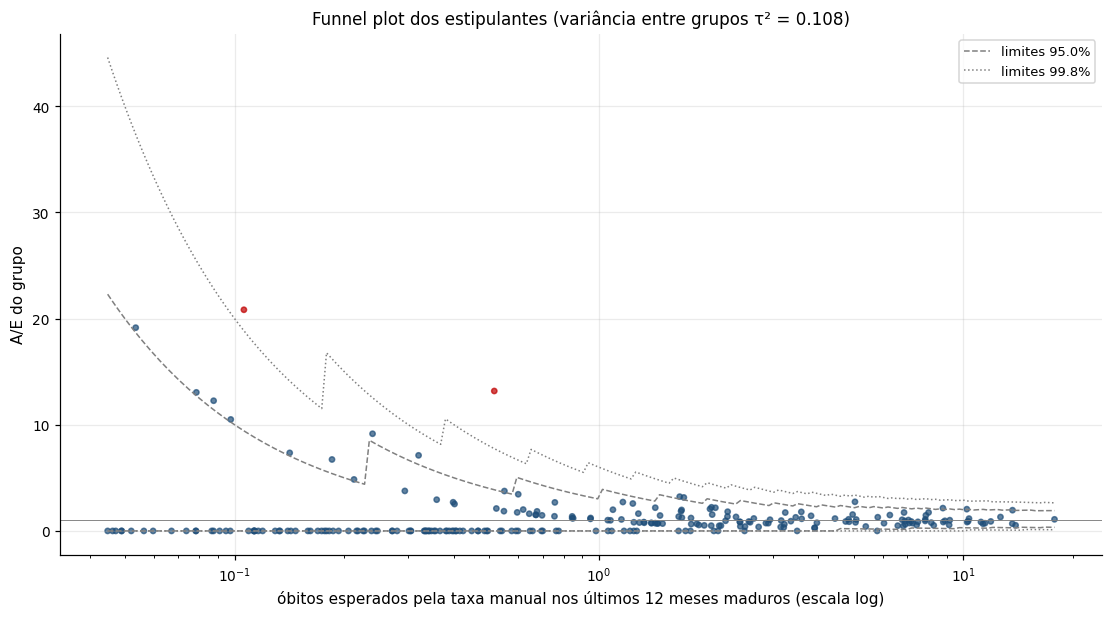

,E_manual,N_ajustado,A/E,lim inf 95.0%,lim sup 95.0%,acima 95.0%,lim inf 99.8%,lim sup 99.8%,acima 99.8%
id_estipulante,,,,,,,,,
EST0074,0.106,2.210,20.829,0.000,9.425,True,0.000,18.851,True
EST0211,0.516,6.802,13.179,0.000,3.875,True,0.000,7.751,True


In [9]:
fig, ax = plt.subplots(figsize=(10, 5.5))
acima = grupos[f"acima {max(NIV):.1%}"]
ax.scatter(grupos["E_manual"], grupos["A/E"], s=12, color=np.where(acima, "#c00000", "#1f4e79"), alpha=0.7)
e = np.geomspace(grupos["E_manual"].min(), grupos["E_manual"].max(), 200)
for n, ls in zip(NIV, ["--", ":"]):
    inf, sup = Mo.limites_poisson(e, n, grupos.attrs["tau2"])
    ax.plot(e, inf, ls, color="grey", lw=1, label=f"limites {n:.1%}"); ax.plot(e, sup, ls, color="grey", lw=1)
ax.axhline(1, color="grey", lw=0.6); ax.set_xscale("log")
ax.set_xlabel(f"óbitos esperados pela taxa manual nos últimos {J} meses maduros (escala log)")
ax.set_ylabel("A/E do grupo"); ax.set_title(f"Funnel plot dos estipulantes (variância entre grupos τ² = {grupos.attrs['tau2']:.3f})")
ax.legend(); fig.savefig(RAIZ / "docs/figuras/operacao_funil.png", dpi=110)
plt.show()
grupos[acima].sort_values("A/E", ascending=False).head(10)

Os grupos acima do limite têm vários óbitos para menos de um esperado: é o perfil de evento com várias mortes
(na carteira sintética, uma hipótese explícita do gerador) ou de problema de cadastro, exatamente o que a investigação
deve separar. Grupos fora do limite superior de 99,8% merecem investigação (cadastro, mudança de atividade, sinistro atípico) e
são exatamente os que a renovação vai reajustar mais. Grupos pequenos ficam dentro do funil mesmo com A/E alto: o
volume não permite distinguir de sorte.

### B3. Gatilhos

In [10]:
gat = Mo.gatilhos(cart, grupos, tabela["meta"], cfg["data_referencia"], cmo)
gat.to_csv(RAIZ / "resultados/operacao_gatilhos.csv", index=False)
gat

,gatilho,disparou,valor,ação
0,A/E 12m da carteira fora do limite de 99.8%,False,1.004 (limites 0.877 a 1.127),recalibrar a taxa manual (champion/challenger)
1,grupos acima do limite de 99.8%,False,0.80% dos grupos (esperado: 0.10%; limites com...,investigar subscrição e cadastro dos grupos
2,idade da experiência que calibrou a tabela,False,12 meses desde o corte (2024-12-31),ciclo anual de recalibração


### B4. Protocolo de revisão (champion/challenger)

Quando um gatilho dispara, ou no ciclo anual:
1. **Desafiante:** o mesmo pipeline (04) com a experiência atualizada, e qualquer mudança proposta (fator novo,
   interação, política de anos excluídos) como candidato adicional.
2. **Teste:** fora do tempo, contra o modelo em produção (champion), com a regra de decisão de `config/manual.yaml`
   (IC por bootstrap por estipulante).
3. **Aprovação:** o desafiante só substitui o champion se a regra o escolher; a decisão, os empates e os testes ficam
   registrados nos metadados da nova `artefatos/fatores_manual.yaml`.
4. **Versionamento:** a tabela anterior fica no histórico do git; cotação e renovação passam a ler a nova.